https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf

In [1]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F
torch.manual_seed(42)

In [2]:
%%capture
! [ -f names.txt ] || wget https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt

In [3]:
df = pd.read_csv("names.txt", header=None)
names = df[0].str.lower()
names[:3]

0      emma
1    olivia
2       ava
Name: 0, dtype: str

In [4]:
# build dataset
blocks = 3

X = [] # [[000], [0,0,2], [0, 2, 18], [2,18,13] ...]
Y = [] # [2, 18, 13, ...]

for name in names:
	context = [0] * blocks
	for c in name:
		idx = ord(c) - ord("a")

		X.append(context) # this context predicts
		Y.append(idx) # this char

		context = context[1:] + [idx] # new context

	X.append(context)
	Y.append(26)

X = torch.tensor(X)
Y = torch.tensor(Y)

N = len(names)
Ntrain = N * 8 // 10

Xtrain, Ytrain = X[:Ntrain], Y[:Ntrain]
Xval, Yval = X[Ntrain:], Y[Ntrain:]

single layer

In [5]:
torch.manual_seed(42)

# embedding matrix (word index, embedding vector)
nvec = 2
EMB = torch.randn(27, nvec)
emb = EMB[Xval]
# (list of contexts, indices of char, embedding vector)
emb.shape

torch.Size([202520, 3, 2])

In [7]:
# concat the embeddings together into one input vector
# [.,.] + [.,.] + [.,.]
nin = nvec * blocks

W1 = torch.randn((nin,300))
b1 = torch.randn(300)

W2 = torch.randn((300,27))
b2 = torch.randn(27)

params = [EMB, W1, b1, W2, b2]
for p in params:
	p.requires_grad = True


lrs = 10**torch.linspace(-3, 0, 1000)
lrsi = []
lossi = []

for i in range(200000):
	batchsize = 32

	# random indices in dataset
	ixs = torch.randint(0, Xtrain.shape[0], (batchsize,))

	# random (context --> char) pairs
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	emb = EMB[ctx] # ctx in embedding form

	layer = torch.tanh(emb.view(-1, nin) @ W1 + b1)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)

	for p in params:
		p.grad = None

	loss.backward()

	lr = 0.1 if i < 100000 else 0.01
	# lr = lrs[i]
	with torch.no_grad():
		for p in params:
			p -= lr * p.grad

	# lrsi.append(lr)
	lossi.append(loss.item())
	
print(loss.item())

2.074845552444458


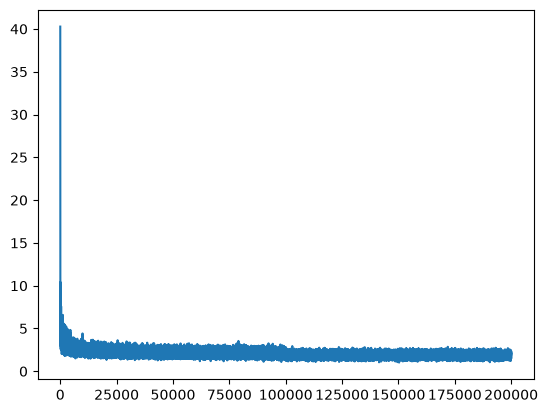

In [8]:
plt.plot(lossi)

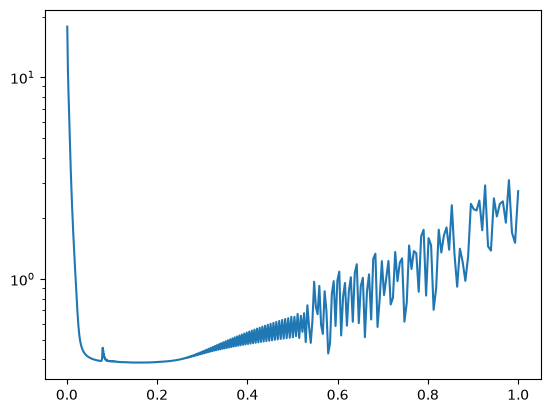

In [ ]:
plt.semilogy(lrsi, lossi)

[0,0,0] -> any char roughly

In [ ]:
-torch.tensor(1/27).log()

tensor(3.2958)

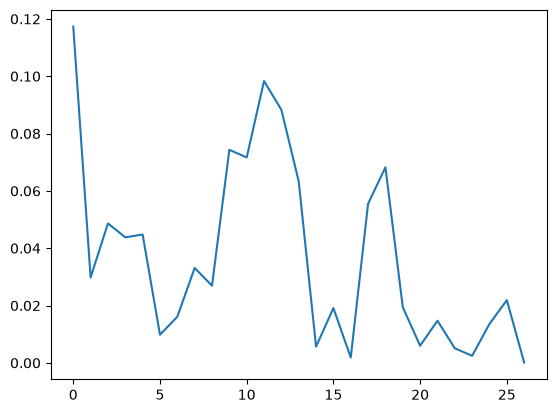

In [12]:
e = EMB[[0,0,0]]
layer = torch.tanh(e.view(-1, nin) @ W1 + b1)
logits = layer @ W2 + b2
probs = torch.softmax(logits.T, axis=0).detach().cpu().numpy()
plt.plot(probs)

Validation

In [10]:
val_loss = []

for i in range(20):
	batchsize = 32

	ixs = torch.randint(0, Xval.shape[0], (batchsize,))

	ctx, target = Xval[ixs], Yval[ixs]
	emb = EMB[ctx]

	layer = torch.tanh(emb.view(-1, nin) @ W1 + b1)
	logits = layer @ W2 + b2
	loss = F.cross_entropy(logits, target)

	val_loss.append(loss.item())

print(loss.item())

2.0972816944122314


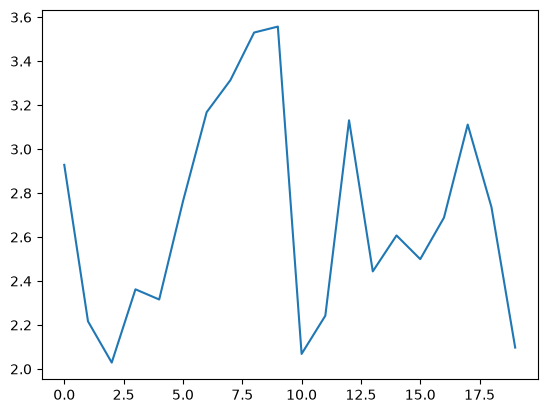

In [13]:
plt.plot(val_loss)

embedding vectors

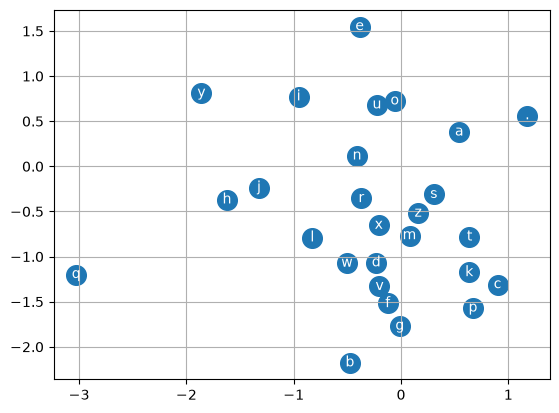

In [14]:
emb_vec = EMB.detach().cpu().numpy()

alpha = "abcdefghijklmnopqrstuvwxyz."

plt.scatter(emb_vec[:,0].data, emb_vec[:,1].data, s=200)
for i in range(emb_vec.shape[0]):
    plt.text(emb_vec[i,0].item(), emb_vec[i,1].item(), alpha[i], ha="center", va="center", color='white')
plt.grid('minor')

generate names

In [15]:
for i in range(20):
	ctx = [0] * blocks
	name = ""
	k = 0

	while k < 20:
		emb = EMB[ctx]

		layer = torch.tanh(emb.view(-1, nin) @ W1 + b1)
		logits = layer @ W2 + b2

		probs = torch.softmax(logits, axis=1)

		cidx = torch.multinomial(probs, num_samples=1, replacement=True).item()
		c = alpha[cidx]
		name += c

		if c == ".":
			break

		ctx = ctx[1:] + [cidx]
		k += 1

	print(name)

ia.
rnly.
kathailey.
shedia.
melyn.
riannorande.
aire.
brielnei.
may.
katty.
haycegnanovis.
aara.
roniquelina.
joley.
dittyn.
jana.
lis.
tilli.
lyn.
adozance.
